In [32]:
from pathlib import Path
from kaggle.api.kaggle_api_extended import KaggleApi

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

import pandas as pd
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

In [14]:

dataset = "nikitarom/planets-dataset"
dataset_dir = Path("data/planets-dataset")

def download_dataset():
    dataset_dir.mkdir(parents=True, exist_ok=True)

    def has_files(folder: Path) -> bool:
        return folder.is_dir() and any(path.is_file() for path in folder.rglob("*"))

    if has_files(dataset_dir):
        print(f"Dataset already present in {dataset_dir}; skipping download. Empty this directory to redownload")
    else:
        try:
            api = KaggleApi()
            api.authenticate()
            api.dataset_download_files(
                dataset,
                path=str(dataset_dir),
                unzip=True,
                quiet=False
            )
        except Exception as exc:
            raise RuntimeError(
                "Kaggle authentication failed. "
                "Check your API token"
            ) from exc

download_dataset()

Dataset already present in data/planets-dataset; skipping download. Empty this directory to redownload


In [25]:
def find_paths():
    classes_dir = next(dataset_dir.rglob("train_classes.csv"))
    train_dir = next(p for p in dataset_dir.rglob("train-jpg") if p.is_dir())
    test_dir = next(p for p in dataset_dir.rglob("test-jpg") if p.is_dir())
    return classes_dir, train_dir, test_dir

def load_data():
    classes_dir, train_dir, _ = find_paths()
    df = pd.read_csv(classes_dir)
    df["tags"] = df["tags"].str.split()
    mlb = MultiLabelBinarizer()
    y = mlb.fit_transform(df["tags"]).astype("float32")
    paths = (train_dir / (df["image_name"] + ".jpg")).astype(str)

    train_p, val_p, train_y, val_y = train_test_split(
        paths, y, test_size=0.2
    )

    class_names = mlb.classes_

    return train_p, val_p, train_y, val_y, class_names

train_p, val_p, train_y, val_y, class_names = load_data()
print (train_p)

14556    data/planets-dataset/planet/planet/train-jpg/t...
7565     data/planets-dataset/planet/planet/train-jpg/t...
15877    data/planets-dataset/planet/planet/train-jpg/t...
24736    data/planets-dataset/planet/planet/train-jpg/t...
5463     data/planets-dataset/planet/planet/train-jpg/t...
                               ...                        
460      data/planets-dataset/planet/planet/train-jpg/t...
38222    data/planets-dataset/planet/planet/train-jpg/t...
8139     data/planets-dataset/planet/planet/train-jpg/t...
11478    data/planets-dataset/planet/planet/train-jpg/t...
2241     data/planets-dataset/planet/planet/train-jpg/t...
Name: image_name, Length: 32383, dtype: str


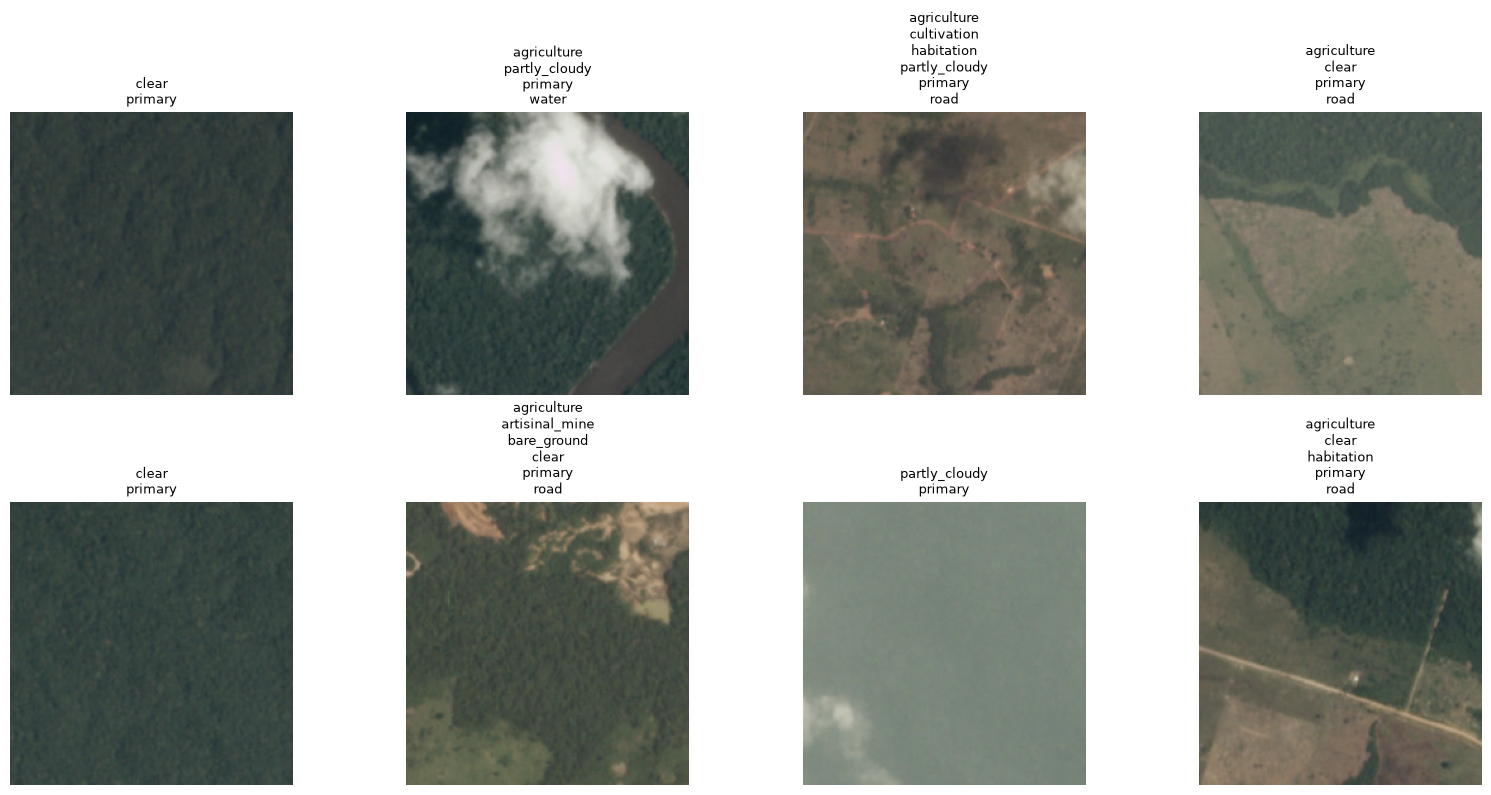

In [37]:
IMG_SIZE = 224
AUTOTUNE = tf.data.AUTOTUNE

def _pil_load(path):
    path = path.decode() if isinstance(path, bytes) else str(path)
    img = Image.open(path).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32)

def load(path, label):
    img = tf.numpy_function(_pil_load, [path], tf.float32)
    img.set_shape((IMG_SIZE, IMG_SIZE, 3))
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, tf.int32))
    return img, label

def prep(img, label):
    return preprocess_input(img), label

def show_preview(ds, class_names, n=8, cols=4):
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(4 * cols, 4 * rows))
    for i, (img, label) in enumerate(ds.take(n)):
        tags = [class_names[j] for j in np.where(label.numpy() == 1)[0]]
        plt.subplot(rows, cols, i + 1)
        plt.imshow(img.numpy().astype("uint8"))
        plt.title("\n".join(tags), fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

def make_ds(paths, labels, training, preview=False, batch=64):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE)
    if preview:
        show_preview(ds, class_names)
    if training:
        ds = ds.map(augment, num_parallel_calls=AUTOTUNE)
    return ds.map(prep, num_parallel_calls=AUTOTUNE).batch(batch).prefetch(AUTOTUNE)

train_ds = make_ds(train_p, train_y, training=True, preview=True)
val_ds   = make_ds(val_p,   val_y,   training=False)